<a href="https://colab.research.google.com/github/MiguelAP6/IAAC/blob/feature%2Fruben/evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
=== COMPARAÇÃO DE MODELOS (EVALUATION) ===

--- Decision Tree ---
              precision    recall  f1-score   support

  Normal (0)       0.98      0.98      0.98      1920
  Ataque (1)       0.51      0.49      0.50        80

    accuracy                           0.96      2000
   macro avg       0.75      0.73      0.74      2000
weighted avg       0.96      0.96      0.96      2000


--- Random Forest ---
              precision    recall  f1-score   support

  Normal (0)       0.96      1.00      0.98      1920
  Ataque (1)       0.62      0.12      0.21        80

    accuracy                           0.96      2000
   macro avg       0.79      0.56      0.59      2000
weighted avg       0.95      0.96      0.95      2000


--- Logistic Regression ---
              precision    recall  f1-score   support

  Normal (0)       0.96      1.00      0.98      1920
  Ataque (1)       1.00      0.03      0.05        80

    accuracy                          

/tmp/ipykernel_2290/1471789981.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=np.array(feature_names)[indices], ax=axes[2], palette='viridis')


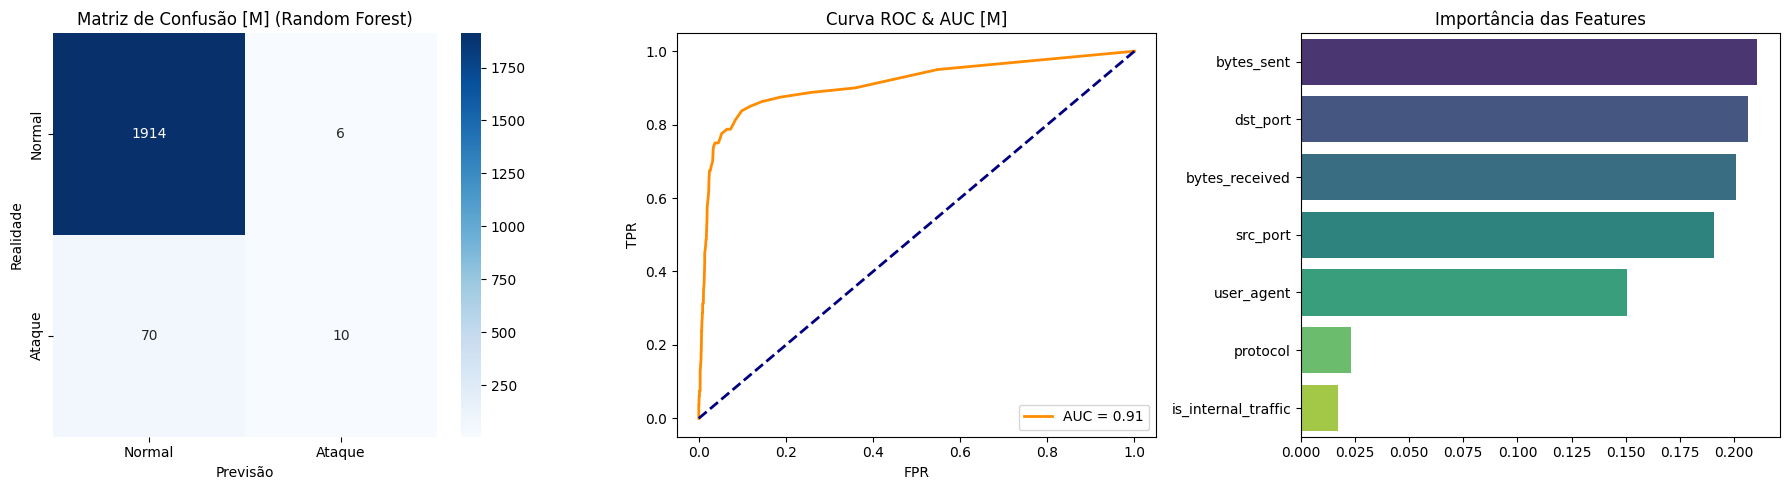

In [ ]:
import os
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# ==============================================================================
# 1. MONTAR O GOOGLE DRIVE
# ==============================================================================
drive.mount('/content/drive')
drive_path = '/content/drive/MyDrive/Projeto_Cybersecurity'

# ==============================================================================
# 2. CARREGAR ARTEFATOS GUARDADOS DO DRIVE
# ==============================================================================
X_test_scaled = joblib.load(f'{drive_path}/models/X_test_scaled.pkl')
y_test = joblib.load(f'{drive_path}/models/y_test.pkl')
feature_names = joblib.load(f'{drive_path}/models/feature_names.pkl')

dt_model = joblib.load(f'{drive_path}/models/decision_tree_model.pkl')
rf_model = joblib.load(f'{drive_path}/models/random_forest_model.pkl')
lr_model = joblib.load(f'{drive_path}/models/logistic_regression_model.pkl')
knn_model = joblib.load(f'{drive_path}/models/knn_model.pkl')

# ==============================================================================
# 3. COMPARAÇÃO E AVALIAÇÃO DOS MODELOS
# ==============================================================================
models = {
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'Logistic Regression': lr_model,
    'KNN': knn_model
}

print("==========================================")
print("=== COMPARAÇÃO DE MODELOS (EVALUATION) ===")
print("==========================================")

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    print(f"\n--- {name} ---")
    print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Ataque (1)']))

# ==============================================================================
# 4. GRÁFICOS DO MELHOR MODELO (Random Forest)
# ==============================================================================
y_pred_rf = rf_model.predict(X_test_scaled)
y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Matriz de Confusão [M]
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal', 'Ataque'], yticklabels=['Normal', 'Ataque'])
axes[0].set_title('Matriz de Confusão [M] (Random Forest)')
axes[0].set_xlabel('Previsão')
axes[0].set_ylabel('Realidade')

# Curva ROC & AUC [M]
fpr, tpr, _ = roc_curve(y_test, y_prob_rf)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.2f}')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_title('Curva ROC & AUC [M]')
axes[1].set_xlabel('FPR')
axes[1].set_ylabel('TPR')
axes[1].legend(loc="lower right")

# Feature Importance
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
sns.barplot(x=importances[indices], y=np.array(feature_names)[indices], ax=axes[2], palette='viridis')
axes[2].set_title('Importância das Features')

plt.tight_layout()
plt.show()